# 02 — Preprocessing & Data Pipeline
Grayscale → CLAHE → aspect-ratio resize + pad (384×384) → 3-channel → ImageNet norm. Same augmentation for all models (no random erasing).

In [1]:
# ============================================================
# Config
# ============================================================
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

DATASET_DIR  = Path("/mnt/g/Research paper/Research paper/dataset of pneomunia/chest_xray")
PROJECT_ROOT = Path("/mnt/g/Research paper/Research paper/Pneumonia-MultiModel-XAI")
SPLITS_DIR   = PROJECT_ROOT / "splits"
CACHE_DIR    = PROJECT_ROOT / "cache_384"
SRC_DIR      = PROJECT_ROOT / "src"
RESULTS_DIR  = PROJECT_ROOT / "results"
for d in (CACHE_DIR, SRC_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

In [2]:
MODULE_SRC = r'''"""Shared data pipeline: CLAHE -> aspect-ratio resize+pad (384) -> 3ch -> ImageNet norm."""
import json
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2

CLASSES = ["NORMAL", "BACTERIA", "VIRUS"]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
IMG_SIZE = 384
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def clahe_resize_pad(gray, size=IMG_SIZE, clip=2.0, tile=8):
    """gray uint8 HxW -> CLAHE -> keep aspect ratio -> zero-pad to size x size."""
    g = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(gray)
    h, w = g.shape
    s = size / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    interp = cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC
    g = cv2.resize(g, (nw, nh), interpolation=interp)
    canvas = np.zeros((size, size), np.uint8)
    top, left = (size - nh) // 2, (size - nw) // 2
    canvas[top:top + nh, left:left + nw] = g
    return canvas


def cached_path(cache_dir, rel_path):
    return Path(cache_dir) / Path(rel_path).with_suffix(".png")


def build_cache(df, raw_dir, cache_dir, size=IMG_SIZE, overwrite=False):
    """Run CLAHE + resize + pad once and store lossless PNGs (fast training)."""
    n_new = 0
    for rel in df["image_path"]:
        out = cached_path(cache_dir, rel)
        if out.exists() and not overwrite:
            continue
        gray = cv2.imread(str(Path(raw_dir) / rel), cv2.IMREAD_GRAYSCALE)
        if gray is None:
            raise IOError(f"Cannot read {rel}")
        out.parent.mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(out), clahe_resize_pad(gray, size))
        n_new += 1
    return n_new


def build_train_aug():
    """Identical for every model. No random erasing."""
    return v2.Compose([
        v2.RandomHorizontalFlip(0.5),
        v2.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),
        v2.ColorJitter(brightness=0.1, contrast=0.1),
    ])


class CXRDataset(Dataset):
    def __init__(self, csv_path, cache_dir, train=False):
        self.df = pd.read_csv(csv_path).reset_index(drop=True)
        self.paths = [cached_path(cache_dir, p) for p in self.df["image_path"]]
        self.labels = [CLASS_TO_IDX[l] for l in self.df["label"]]
        self.aug = build_train_aug() if train else None
        self.to_tensor = v2.Compose([
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("L")
        if self.aug is not None:
            img = self.aug(img)
        img = img.convert("RGB")                 # grayscale -> 3 channels
        return self.to_tensor(img), self.labels[i]


def class_weights(labels, n_classes=len(CLASSES)):
    counts = np.bincount(labels, minlength=n_classes).astype(np.float64)
    w = counts.sum() / (n_classes * counts)
    return torch.tensor(w, dtype=torch.float32)


def make_mix_collate(num_classes=len(CLASSES), alpha=1.0):
    """Optional MixUp/CutMix (random pick per batch). Returns soft labels."""
    mix = v2.RandomChoice([v2.CutMix(alpha=alpha, num_classes=num_classes),
                           v2.MixUp(alpha=alpha, num_classes=num_classes)])
    def collate(batch):
        x, y = torch.utils.data.default_collate(batch)
        return mix(x, y)
    return collate


def _worker_init(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)


def make_loaders(fold, splits_dir, cache_dir, batch_size=16, num_workers=4,
                 seed=42, use_mix=False):
    splits_dir = Path(splits_dir)
    ds = {r: CXRDataset(splits_dir / f"fold{fold}_{r}.csv", cache_dir, train=(r == "train"))
          for r in ["train", "val", "test"]}
    g = torch.Generator(); g.manual_seed(seed)
    train_loader = DataLoader(ds["train"], batch_size=batch_size, shuffle=True, drop_last=True,
                              num_workers=num_workers, pin_memory=True, generator=g,
                              worker_init_fn=_worker_init,
                              collate_fn=make_mix_collate() if use_mix else None,
                              persistent_workers=num_workers > 0)
    eval_kw = dict(batch_size=batch_size * 2, shuffle=False, num_workers=num_workers,
                   pin_memory=True, persistent_workers=num_workers > 0)
    return (train_loader, DataLoader(ds["val"], **eval_kw), DataLoader(ds["test"], **eval_kw),
            class_weights(ds["train"].labels), ds)
'''

(SRC_DIR / "pneumo_data.py").write_text(MODULE_SRC, encoding="utf-8")

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
import importlib, pneumo_data
importlib.reload(pneumo_data)
from pneumo_data import *
print("Saved:", SRC_DIR / "pneumo_data.py")

Saved: /mnt/g/Research paper/Research paper/Pneumonia-MultiModel-XAI/src/pneumo_data.py


In [3]:
# ============================================================
# Build 384x384 CLAHE cache (one-time, lossless PNG)
# ============================================================
meta = pd.read_csv(SPLITS_DIR / "kermany_patient_splits.csv")
n_new = build_cache(meta, DATASET_DIR, CACHE_DIR)
n_cached = sum(1 for _ in CACHE_DIR.rglob("*.png"))
print(f"Newly cached: {n_new} | Total cached: {n_cached} / {len(meta)}")
assert n_cached == len(meta)

Newly cached: 5856 | Total cached: 5856 / 5856


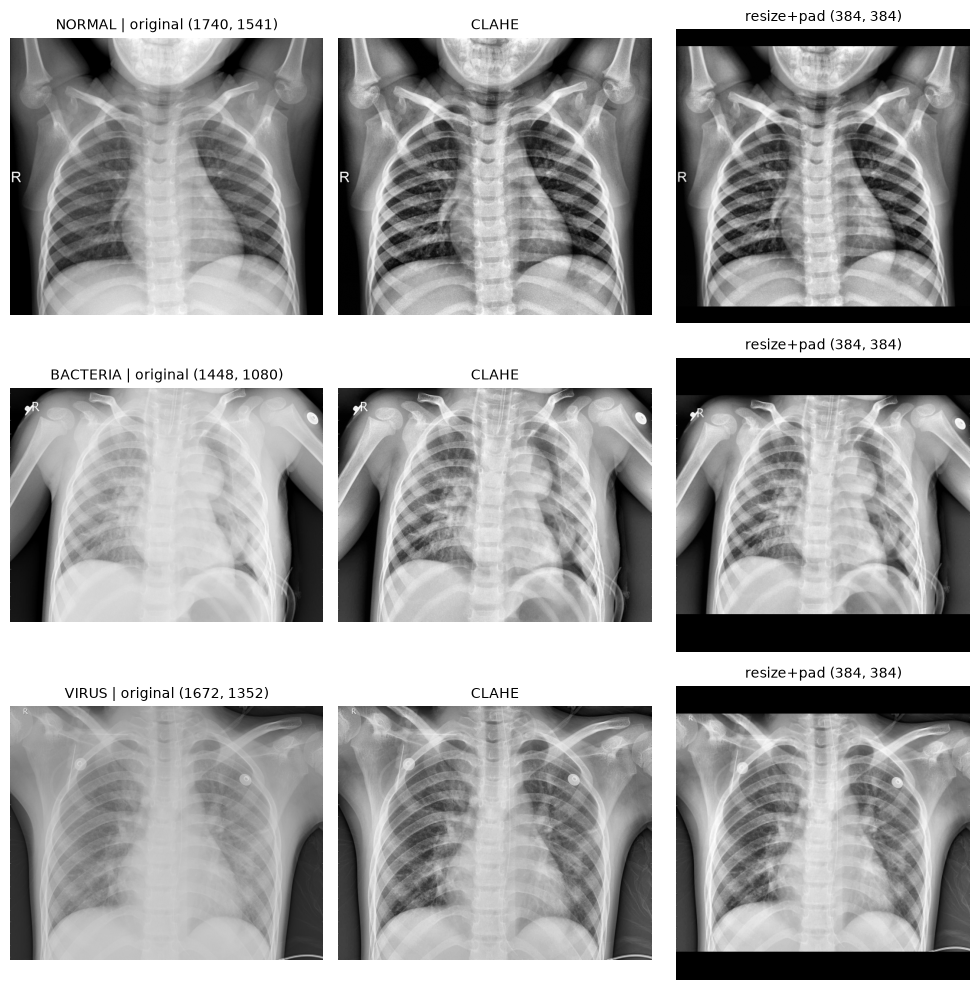

In [4]:
# ============================================================
# Before / After (one image per class)
# ============================================================
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for i, cls in enumerate(CLASSES):
    row = meta[meta["label"] == cls].sample(1, random_state=7).iloc[0]
    raw  = cv2.imread(str(DATASET_DIR / row["image_path"]), cv2.IMREAD_GRAYSCALE)
    clah = cv2.createCLAHE(2.0, (8, 8)).apply(raw)
    fin  = cv2.imread(str(cached_path(CACHE_DIR, row["image_path"])), cv2.IMREAD_GRAYSCALE)
    for ax, im, t in zip(axes[i], [raw, clah, fin],
                         [f"{cls} | original {raw.shape[::-1]}", "CLAHE", f"resize+pad {fin.shape[::-1]}"]):
        ax.imshow(im, cmap="gray"); ax.set_title(t, fontsize=10); ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "preprocessing_before_after.png", dpi=300, bbox_inches="tight")
plt.show()

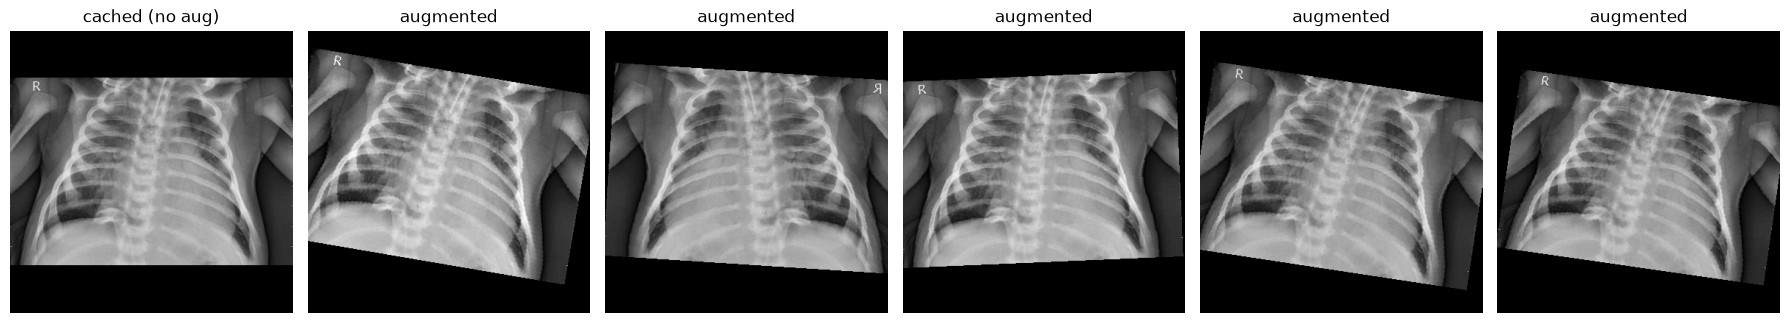

In [5]:
# ============================================================
# Augmentation preview (train-only transform)
# ============================================================
from PIL import Image
row = meta.sample(1, random_state=3).iloc[0]
base = Image.open(cached_path(CACHE_DIR, row["image_path"])).convert("L")
aug = build_train_aug()

fig, axes = plt.subplots(1, 6, figsize=(18, 3.4))
axes[0].imshow(base, cmap="gray"); axes[0].set_title("cached (no aug)")
for ax in axes[1:]:
    ax.imshow(aug(base), cmap="gray"); ax.set_title("augmented")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "augmentation_preview.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
# ============================================================
# DataLoader sanity check (fold 0)
# ============================================================
import torch
train_loader, val_loader, test_loader, cw, ds = make_loaders(
    fold=0, splits_dir=SPLITS_DIR, cache_dir=CACHE_DIR, batch_size=16, num_workers=2)

print("Train / Val / Test:", len(ds["train"]), len(ds["val"]), len(ds["test"]))
print("Class weights [NORMAL, BACTERIA, VIRUS]:", cw.numpy().round(3))

x, y = next(iter(train_loader))
print("Batch:", tuple(x.shape), x.dtype, "| labels:", y.tolist())
print(f"Tensor mean {x.mean():.3f} | std {x.std():.3f} | min {x.min():.2f} | max {x.max():.2f}")
assert x.shape == (16, 3, 384, 384)

xv, yv = next(iter(val_loader))
print("Val batch:", tuple(xv.shape))

Train / Val / Test: 3513 1172 1171
Class weights [NORMAL, BACTERIA, VIRUS]: [1.233 0.702 1.308]
Batch: (16, 3, 384, 384) torch.float32 | labels: [0, 2, 0, 0, 1, 1, 1, 0, 0, 2, 1, 1, 0, 0, 0, 0]
Tensor mean -0.312 | std 1.305 | min -2.12 | max 2.64
Val batch: (32, 3, 384, 384)


In [7]:
# ============================================================
# Optional MixUp/CutMix check
# ============================================================
mix_loader = make_loaders(0, SPLITS_DIR, CACHE_DIR, batch_size=16, num_workers=0, use_mix=True)[0]
xm, ym = next(iter(mix_loader))
print("Mix batch:", tuple(xm.shape), "| soft labels:", tuple(ym.shape))

Mix batch: (16, 3, 384, 384) | soft labels: (16, 3)


In [8]:
# ============================================================
# Save preprocessing config
# ============================================================
cfg = {"img_size": IMG_SIZE, "clahe_clip": 2.0, "clahe_tile": 8, "pad_value": 0,
       "mean": IMAGENET_MEAN, "std": IMAGENET_STD, "classes": CLASSES,
       "aug": {"hflip": 0.5, "rotation_deg": 10, "translate": 0.05, "scale": 0.05,
               "brightness": 0.1, "contrast": 0.1, "random_erasing": False}}
(PROJECT_ROOT / "preprocess_config.json").write_text(json.dumps(cfg, indent=2))
print(json.dumps(cfg, indent=2))

{
  "img_size": 384,
  "clahe_clip": 2.0,
  "clahe_tile": 8,
  "pad_value": 0,
  "mean": [
    0.485,
    0.456,
    0.406
  ],
  "std": [
    0.229,
    0.224,
    0.225
  ],
  "classes": [
    "NORMAL",
    "BACTERIA",
    "VIRUS"
  ],
  "aug": {
    "hflip": 0.5,
    "rotation_deg": 10,
    "translate": 0.05,
    "scale": 0.05,
    "brightness": 0.1,
    "contrast": 0.1,
    "random_erasing": false
  }
}
